In [3]:
%pip install pandas matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.


In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.labelsize"] = 11

In [5]:
df = pd.read_csv("ev_vs_petrol_dataset_cleaned.csv")

# Clean column names, including the formatting artifacts in the header
df.columns = (
    df.columns
    .str.replace(r"^\*+", "", regex=True)
    .str.replace(r"&#x66;", "f", regex=False)
    .str.strip()
)

# Convert relevant columns to numeric
numeric_columns = [
    "year",
    "ev_sales",
    "petrol_car_sales",
    "diesel_car_sales",
    "total_vehicle_sales",
    "ev_market_share",
    "charging_stations",
    "fuel_price_usd_per_liter",
    "co2_emissions_transport_mt"
]

for col in numeric_columns:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors="coerce")

df["country"] = df["country"].astype("string").str.strip()

# Remove rows missing the identifiers needed for country-year analysis
df = df.dropna(subset=["country", "year"])
df["year"] = df["year"].astype(int)

print("Dataset shape:", df.shape)
print(df.head())
print("\nMissing values:\n", df.isnull().sum())

Dataset shape: (400, 16)
     country  year  ev_sales  petrol_car_sales  diesel_car_sales  \
0  Australia  2010        99            864092            155472   
1  Australia  2011       220            920414            165048   
2  Australia  2012       329            914469            163679   
3  Australia  2013       678            944469            169944   
4  Australia  2014      1035            960445            171628   

   total_vehicle_sales  ev_market_share  charging_stations  avg_ev_range_km  \
0              1019663             0.01                  0              124   
1              1085682             0.02                105              133   
2              1078477             0.03                191              135   
3              1115091             0.06                306              143   
4              1133108             0.09                408              151   

   fuel_price_usd_per_liter  electricity_price_usd_per_kwh  \
0                     1.090  

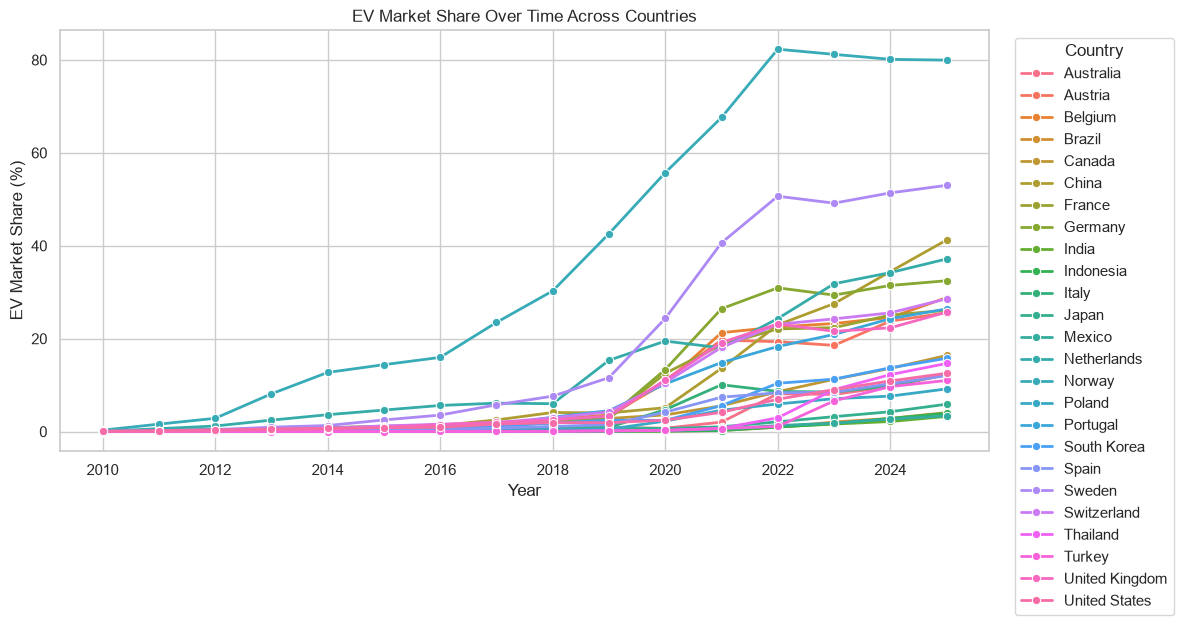

Top 10 Countries by EV Market Share in 2025
       Country EV Market Share (%)
        Norway              79.96%
        Sweden              53.00%
         China              41.23%
   Netherlands              37.15%
       Germany              32.47%
       Belgium              28.82%
   Switzerland              28.58%
      Portugal              26.40%
        France              26.10%
United Kingdom              25.70%


In [19]:
sns.set_theme(style="whitegrid")

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=df,
    x="year",
    y="ev_market_share",
    hue="country",
    marker="o",
    linewidth=2
)

plt.title("EV Market Share Over Time Across Countries")
plt.xlabel("Year")
plt.ylabel("EV Market Share (%)")
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

# Get the latest year in the dataset
latest_year = df["year"].max()

# Find the top 10 countries by EV market share
top_10 = (
    df[df["year"] == latest_year]
    .groupby("country")["ev_market_share"]
    .mean()
    .sort_values(ascending=False)
    .head(10)
    .reset_index()
)

# Rename columns for display
top_10.columns = ["Country", "EV Market Share (%)"]

# Print results
print(f"Top 10 Countries by EV Market Share in {latest_year}")
print(top_10.to_string(index=False, formatters={
    "EV Market Share (%)": "{:.2f}%".format
}))

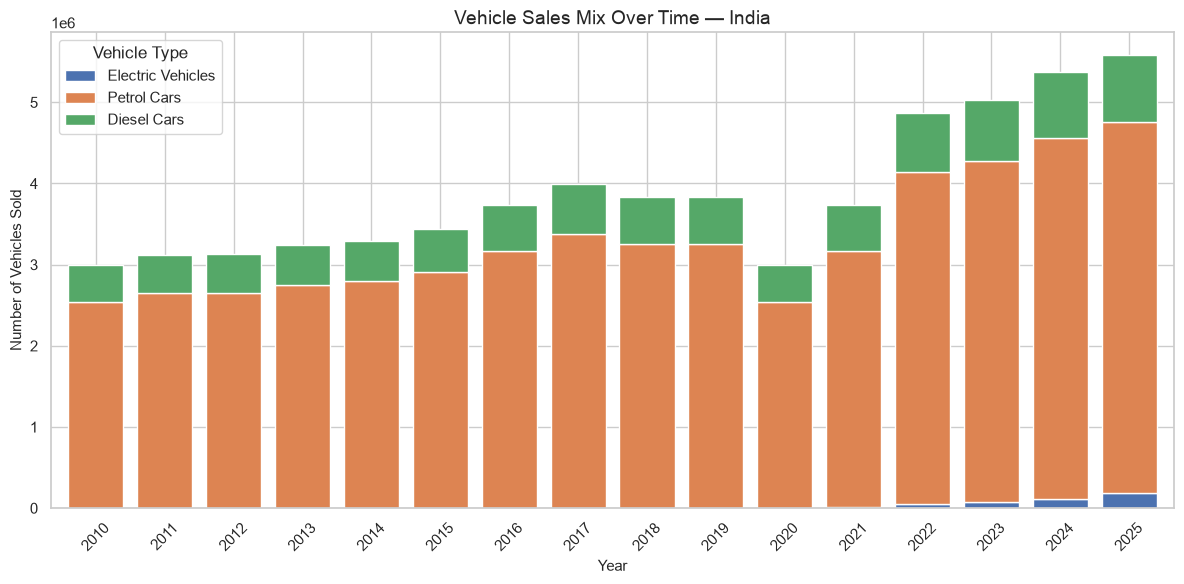

In [13]:
# Change this to any country present in your dataset
selected_country = df["country"].dropna().iloc[141]

sales_columns = [
    "ev_sales",
    "petrol_car_sales",
    "diesel_car_sales"
]

# Aggregate sales by year for the selected country
country_sales = (
    df[df["country"] == selected_country]
    .groupby("year")[sales_columns]
    .sum(min_count=1)
    .sort_index()
)

ax = country_sales.plot(
    kind="bar",
    stacked=True,
    figsize=(12, 6),
    width=0.8
)

ax.set_title(f"Vehicle Sales Mix Over Time — {selected_country}")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Vehicles Sold")
ax.legend(
    ["Electric Vehicles", "Petrol Cars", "Diesel Cars"],
    title="Vehicle Type"
)

plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

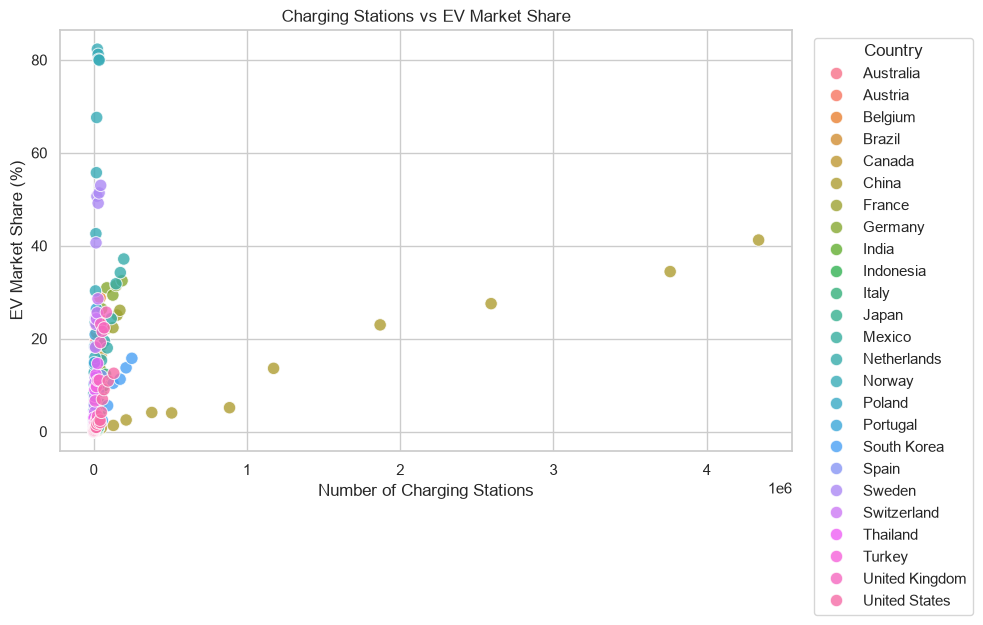

In [15]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df,
    x="charging_stations",
    y="ev_market_share",
    hue="country",
    s=80,
    alpha=0.8
)

plt.title("Charging Stations vs EV Market Share")
plt.xlabel("Number of Charging Stations")
plt.ylabel("EV Market Share (%)")
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()

/var/folders/vh/15l82z8j1rb1p91_45npmgzc0000gn/T/ipykernel_75676/2995050948.py:24: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  plt.tight_layout()
/Users/pranavakorlahalli/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


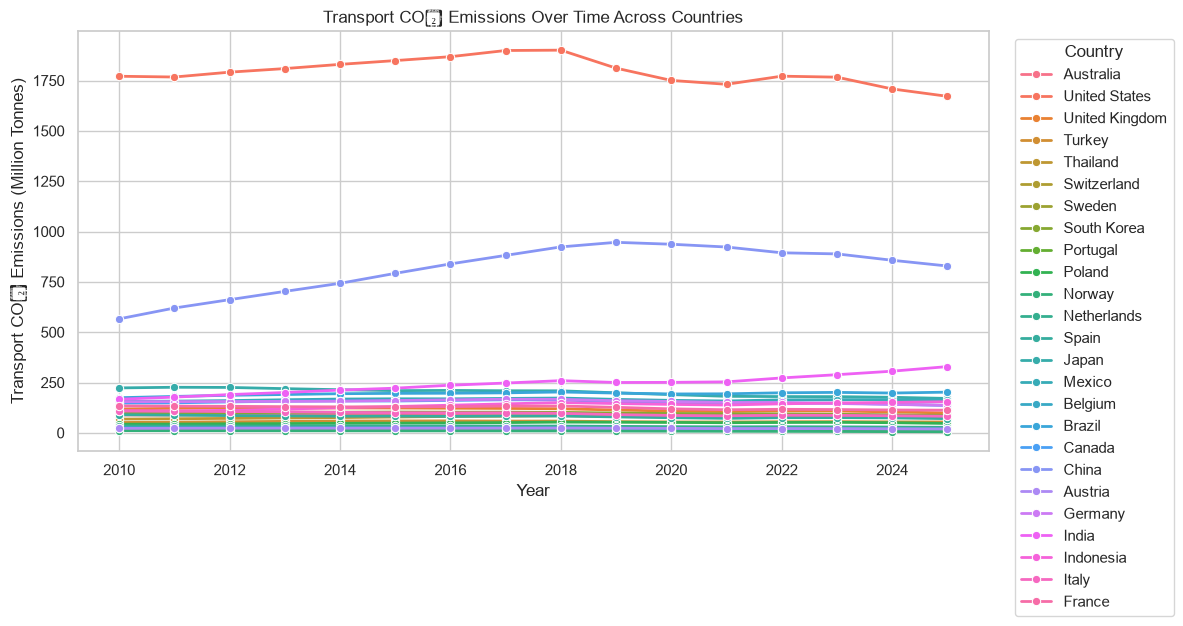

In [16]:
# Aggregate emissions by year and country
emissions = (
    df.groupby(["year", "country"], as_index=False)
      ["co2_emissions_transport_mt"]
      .mean()
      .sort_values("year")
)

plt.figure(figsize=(12, 6))

sns.lineplot(
    data=emissions,
    x="year",
    y="co2_emissions_transport_mt",
    hue="country",
    marker="o",
    linewidth=2
)

plt.title("Transport CO₂ Emissions Over Time Across Countries")
plt.xlabel("Year")
plt.ylabel("Transport CO₂ Emissions (Million Tonnes)")
plt.legend(title="Country", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()